# 02 – Distributions and Outliers

**Objective:** analyse the distribution of the target (`price`) and of the main numerical and categorical features, detect outliers and erroneous extreme values, and decide how to treat them before modelling.

**Input:** `data/processed/listings_00.parquet` (output of notebook 00).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_parquet("../data/processed/listings_00.parquet")
df.shape

(23109, 78)

In [2]:
main_num_cols = ["price", "accommodates", "bedrooms", "beds", "bathrooms",
                 "minimum_nights", "maximum_nights", "number_of_reviews",
                 "review_scores_rating", "availability_365"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
price,18785.0,208.632525,543.628283,9.13,95.45,151.00,224.50,36883.0
accommodates,23109.0,3.256913,1.934129,1.00,2.00,3.00,4.00,16.0
bedrooms,23097.0,1.396848,1.031847,0.00,1.00,1.00,2.00,50.0
beds,22535.0,2.039405,2.065032,1.00,1.00,2.00,2.00,167.0
bathrooms,23091.0,1.307479,0.741310,0.00,1.00,1.00,1.50,19.0
minimum_nights,21380.0,8.873901,26.244603,1.00,1.00,2.00,5.00,1125.0
maximum_nights,21380.0,585.105519,424.502033,1.00,365.00,365.00,1125.00,11111.0
number_of_reviews,23109.0,65.981436,111.763542,0.00,2.00,22.00,80.00,1600.0
review_scores_rating,19294.0,4.640686,0.480326,0.00,4.55,4.75,4.91,5.0
availability_365,23109.0,159.547319,136.263132,0.00,1.00,151.00,298.00,365.0


## 1. Target variable: `price`

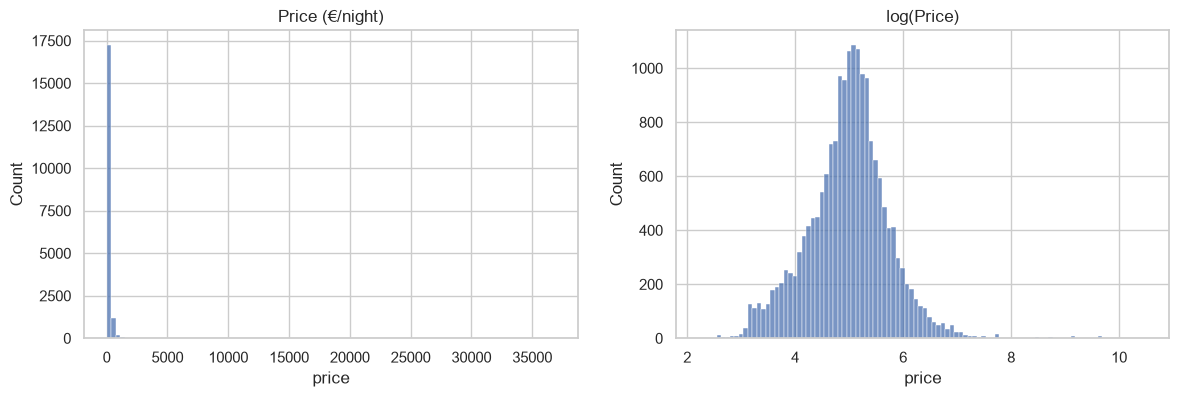

Skewness price:      31.54
Skewness log(price): 0.21


In [3]:
price = df["price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(price, bins=100, ax=axes[0])
axes[0].set_title("Price (€/night)")
sns.histplot(np.log(price), bins=100, ax=axes[1])
axes[1].set_title("log(Price)")
plt.show()

print(f"Skewness price:      {price.skew():.2f}")
print(f"Skewness log(price): {np.log(price).skew():.2f}")

The raw price is extremely right-skewed (skewness ≈ 31.5): most listings cost less than 250 €/night, but a few reach tens of thousands. After a log transformation the distribution becomes almost symmetric (skewness ≈ 0.2). **Conclusion:** the model should predict `log(price)` instead of `price`, and outliers should be evaluated on the log scale.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on price:      [{low:.1f}, {high:.1f}] €  -> {n_out} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(price): [{np.exp(log_low):.1f}, {np.exp(log_high):.1f}] €  -> {n_out_log} outliers ({n_out_log/len(price):.1%})")

IQR on price:      [-98.1, 418.1] €  -> 1219 outliers (6.5%)
IQR on log(price): [26.5, 809.8] €  -> 609 outliers (3.2%)


In [5]:
extreme = df[df["price"] >= 5000]
print(f"{len(extreme)} listings with price >= 5,000 €/night")
print(extreme["host_id"].value_counts().head(3))

extreme[["price", "host_id", "room_type", "accommodates",
         "number_of_reviews", "availability_365"]].sort_values("price", ascending=False)

28 listings with price >= 5,000 €/night
host_id
17011402     11
712177646    10
137289804     1
Name: count, dtype: int64


,price,host_id,room_type,accommodates,number_of_reviews,availability_365
6046,36883.00,17011402,Entire home/apt,6,2,351
17978,15000.00,712177646,Entire home/apt,4,0,365
18025,15000.00,712177646,Entire home/apt,4,0,365
18024,15000.00,712177646,Entire home/apt,3,0,365
17986,15000.00,712177646,Private room,2,0,364
17983,15000.00,712177646,Private room,3,0,365
17981,15000.00,712177646,Private room,2,0,365
17980,15000.00,712177646,Private room,2,0,365
17979,15000.00,712177646,Entire home/apt,4,0,365
17827,15000.00,712177646,Entire home/apt,7,0,365


In [6]:
mid = df[(df["price"] > 2921) & (df["price"] < 5000)]
print(f"{len(mid)} listings between 2,921 and 5,000 €/night")
mid[["price", "host_id", "property_type", "accommodates", "bedrooms",
     "number_of_reviews", "availability_365"]].sort_values("price")

10 listings between 2,921 and 5,000 €/night


,price,host_id,property_type,accommodates,bedrooms,number_of_reviews,availability_365
6634,2965.33,8195907,Entire rental unit,6,6.0,6,364
15851,2977.71,8195907,Entire rental unit,6,6.0,0,365
22607,3200.00,1754285334325612283,Entire rental unit,6,3.0,0,2
18256,3512.00,719696112,Entire serviced apartment,3,1.0,41,358
22862,4055.20,283223016,Entire home,6,3.0,0,365
21196,4200.00,1700176589928376701,Shared room in rental unit,1,0.0,0,365
14704,4467.00,278467498,Entire home,4,2.0,0,365
11369,4644.59,557936291,Entire rental unit,4,2.0,0,269
3803,4714.00,42196839,Entire home,8,5.0,0,89
9361,4720.00,488190941,Entire rental unit,4,0.0,0,269


In [7]:
log_low3, log_high3 = iqr_bounds(log_price, k=3)
upper_price = np.exp(log_high3)
print(f"Extreme-outlier threshold (3·IQR on log scale): {upper_price:.0f} €/night")

n_before = len(df)
df = df[~(df["price"] > upper_price)]
print(f"Removed {n_before - len(df)} listings with price > {upper_price:.0f} €/night")
df.shape

Extreme-outlier threshold (3·IQR on log scale): 2921 €/night
Removed 38 listings with price > 2921 €/night


(23071, 78)

### Decision on price outliers

- **Extreme values are errors, not luxury listings.** The 28 listings above 5,000 €/night are mostly ordinary flats and private rooms; 21 of them belong to just two hosts (one with 11 listings at exactly 15,000 €), almost none have reviews and most are available all year. The 10 listings between 2,921 and 5,000 € follow the same pattern (8 of them have no reviews), with one doubtful case: a serviced apartment for 3 guests at 3,512 € with 41 reviews, which may be a monthly price entered as nightly. These look like placeholder prices used to block bookings.
- **Action 1 – remove extreme outliers:** listings above the extreme-outlier fence (Q3 + 3·IQR on the log scale ≈ 2,921 €/night, Tukey's criterion for extreme outliers) are removed: **38 listings (0.2% of priced listings)**.
- **Action 2 – keep moderate outliers:** the 1.5·IQR rule on the log scale flags 609 listings outside 26.5–810 €/night. Most of the cheap ones are private or shared rooms, which plausibly cost less; they represent real market segments and are kept. Modelling `log(price)` will limit their influence.
- Applying the IQR rule to the raw price is not appropriate: it flags 6.5% of listings and gives a negative lower bound.

## 2. Main numerical features

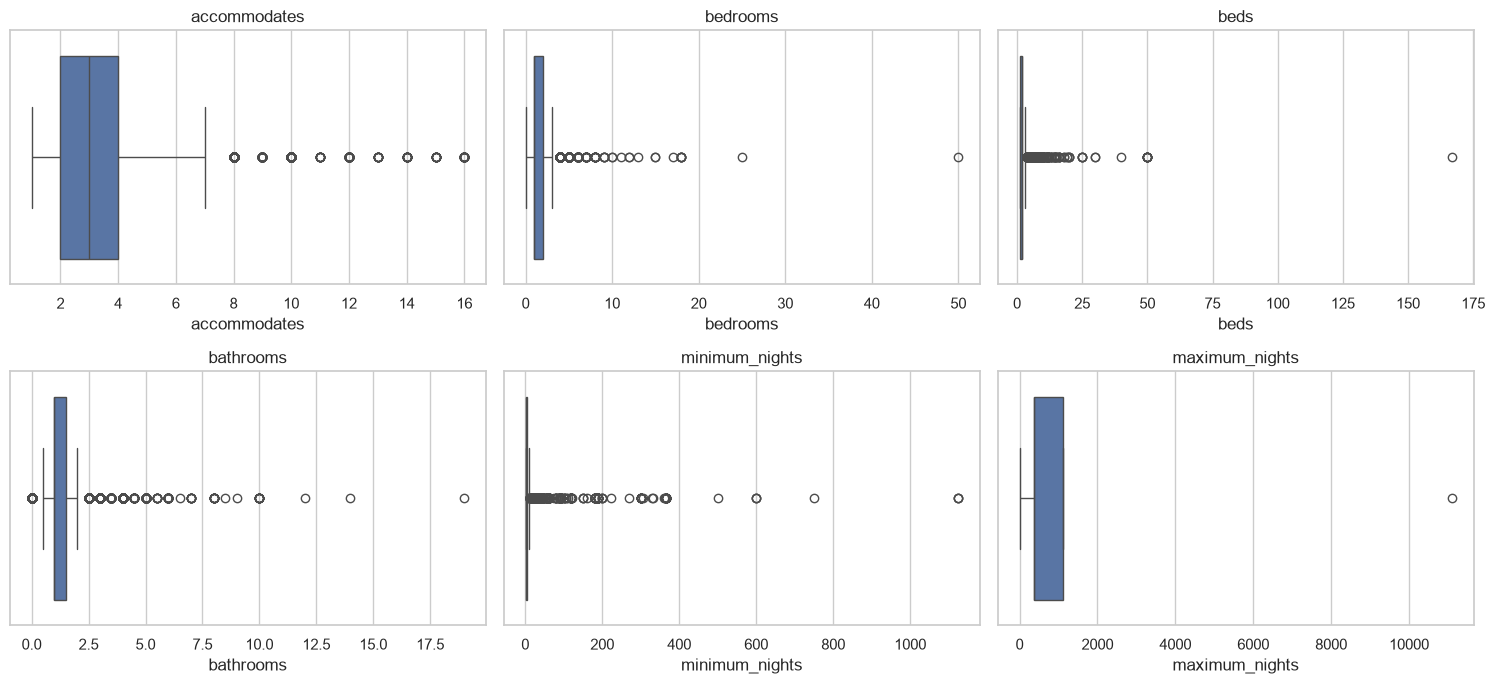

In [8]:
feat_cols = ["accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights", "maximum_nights"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Investigating extreme values before treating them
Before applying any treatment, we inspect which listings would be affected by each candidate rule.

In [9]:
inconsistent = (df["bedrooms"] > df["accommodates"]) | (df["beds"] > 2 * df["accommodates"])
print(f"{inconsistent.sum()} listings with more bedrooms than guests or more than 2 beds per guest")
print(df.loc[inconsistent, "room_type"].value_counts())

df.loc[inconsistent, ["property_type", "room_type", "accommodates", "bedrooms", "beds", "bathrooms"]] \
  .sort_values("bedrooms", ascending=False).head(10)

236 listings with more bedrooms than guests or more than 2 beds per guest
room_type
Private room       200
Shared room         25
Entire home/apt     11
Name: count, dtype: int64


,property_type,room_type,accommodates,bedrooms,beds,bathrooms
21377,Room in hotel,Private room,1,50.0,1.0,1.0
5762,Private room in hostel,Private room,6,25.0,167.0,1.0
14761,Room in hotel,Private room,2,18.0,25.0,14.0
5457,Room in boutique hotel,Private room,2,18.0,1.0,1.5
14767,Room in hotel,Private room,2,18.0,25.0,1.0
14769,Room in hotel,Private room,1,18.0,25.0,2.0
14768,Room in hotel,Private room,2,18.0,25.0,2.0
21766,Room in boutique hotel,Private room,2,17.0,16.0,1.0
21511,Private room in chalet,Private room,2,15.0,1.0,1.0
1037,Private room in rental unit,Private room,1,13.0,1.0,1.0


In [10]:
caps = df[["bedrooms", "beds", "bathrooms"]].quantile(0.99)
above_cap = (df["bedrooms"] > caps["bedrooms"]) | (df["beds"] > caps["beds"]) | (df["bathrooms"] > caps["bathrooms"])

print(f"{above_cap.sum()} listings above the 99th percentile in bedrooms, beds or bathrooms")
print(df.loc[above_cap, "room_type"].value_counts())

df.loc[above_cap & (df["room_type"] == "Entire home/apt"),
       ["property_type", "accommodates", "bedrooms", "beds", "bathrooms", "price"]].head(10)

381 listings above the 99th percentile in bedrooms, beds or bathrooms
room_type
Entire home/apt    203
Private room       144
Shared room         34
Name: count, dtype: int64


,property_type,accommodates,bedrooms,beds,bathrooms,price
97,Entire rental unit,10,3.0,8.0,1.0,151.21
388,Entire rental unit,12,5.0,7.0,5.5,541.00
457,Entire rental unit,10,3.0,9.0,2.0,201.73
836,Entire home,16,8.0,10.0,5.5,1072.00
928,Entire serviced apartment,8,3.0,9.0,2.0,419.00
1028,Entire rental unit,15,5.0,10.0,2.0,377.00
1092,Entire rental unit,14,4.0,8.0,2.0,501.50
1134,Entire rental unit,9,4.0,8.0,1.0,1660.42
1135,Entire rental unit,9,4.0,8.0,1.0,1736.87
1152,Entire rental unit,16,7.0,13.0,4.5,700.00


In [11]:
df.loc[df["minimum_nights"] > 365,
       ["property_type", "room_type", "minimum_nights", "maximum_nights",
        "price", "number_of_reviews", "availability_365"]]

,property_type,room_type,minimum_nights,maximum_nights,price,number_of_reviews,availability_365
927,Entire condo,Entire home/apt,750.0,1125.0,NaN,182,365
1501,Entire rental unit,Entire home/apt,500.0,1125.0,NaN,20,364
1702,Private room in rental unit,Private room,600.0,1125.0,NaN,197,270
1791,Private room in rental unit,Private room,1125.0,1125.0,NaN,59,270
2322,Private room in home,Private room,600.0,1125.0,NaN,24,90
2549,Private room in home,Private room,600.0,1125.0,NaN,18,0
3788,Entire home,Entire home/apt,1125.0,1125.0,NaN,0,89
4121,Private room in condo,Private room,1125.0,1125.0,NaN,0,363


In [12]:
df["maximum_nights"].value_counts().head(10)

maximum_nights
365.0     7901
1125.0    6646
999.0     1021
30.0       574
125.0      439
330.0      390
90.0       354
7.0        267
60.0       252
180.0      244
Name: count, dtype: int64

In [13]:
size_cols = ["bedrooms", "beds", "bathrooms"]

rooms_inconsistent = inconsistent & (df["room_type"] != "Entire home/apt")
df.loc[rooms_inconsistent, size_cols] = np.nan
print(f"Size features set to NaN in {rooms_inconsistent.sum()} inconsistent rooms")
print(f"Inconsistent entire homes kept as they are: {(inconsistent & ~rooms_inconsistent).sum()}")
print(df[size_cols].describe().T[["count", "max"]])

df["long_stay"] = df["minimum_nights"] >= 30
print(f"\nListings with minimum stay >= 30 nights: {df['long_stay'].mean():.1%}")
print(df.groupby("long_stay")["price"].agg(["count", "median"]))
df.shape

Size features set to NaN in 225 inconsistent rooms
Inconsistent entire homes kept as they are: 11
             count   max
bedrooms   22834.0  15.0
beds       22275.0  20.0
bathrooms  22829.0   9.0

Listings with minimum stay >= 30 nights: 13.7%
           count   median
long_stay                
False      16423  159.000
True        2324   94.495


(23071, 79)

### Decisions on feature outliers

Each extreme value was inspected before deciding on a treatment:

- **Bedrooms, beds and bathrooms – inconsistent definition, not luxury listings.** 236 listings have more bedrooms than guests or more than two beds per guest (e.g. a hotel room for 1 guest with 50 bedrooms, a hostel room with 167 beds). 225 of them are private or shared rooms: for these listings Airbnb reports the size of the whole building or shared flat, not of the room being rented. **Action:** for these 225 rooms, the three size values are set to `NaN` (true value unknown) and will be imputed in the modelling stage. The listings are kept because their price is valid.
- **Inconsistent entire homes are kept.** The other 11 are entire flats with more bedrooms than allowed guests (e.g. a 3-bedroom flat for 1 guest). This is plausible, since hosts can limit the number of guests, so their values are not modified.
- **Capping at the 99th percentile was rejected.** Of the 381 listings above the 99th percentile, 203 are entire homes with consistent data (e.g. 8 bedrooms for 16 guests). They are legitimate large properties, and capping them would remove real information.
- **`minimum_nights` > 365 (8 listings).** All of them have no price, and several have many past reviews: they are listings blocked by their hosts. **No action here:** they will be excluded together with the rest of listings without price (notebook 01).
- **`maximum_nights`.** 67% of listings use default or "no limit" values (365, 1,125, 999), so the variable mostly reflects platform defaults rather than host decisions. **Action:** values are kept, but we recommend not using it as a model feature.
- **New feature `long_stay`.** 13.7% of listings require a minimum stay of 30 nights or more (mid-term rentals). Their median price is 94 €/night versus 159 € for the rest, so they represent a different market segment. A boolean feature `long_stay` is created so the model can capture it. (This definition is refined in section 4.)

## 3. Categorical features

In [14]:
cat_cols = ["room_type", "property_type", "neighbourhood_group_cleansed", "neighbourhood_cleansed"]

pd.DataFrame({
    "n_categories": df[cat_cols].nunique(),
    "missing": df[cat_cols].isna().sum()
})

,n_categories,missing
room_type,4,0
property_type,60,0
neighbourhood_group_cleansed,21,0
neighbourhood_cleansed,128,0


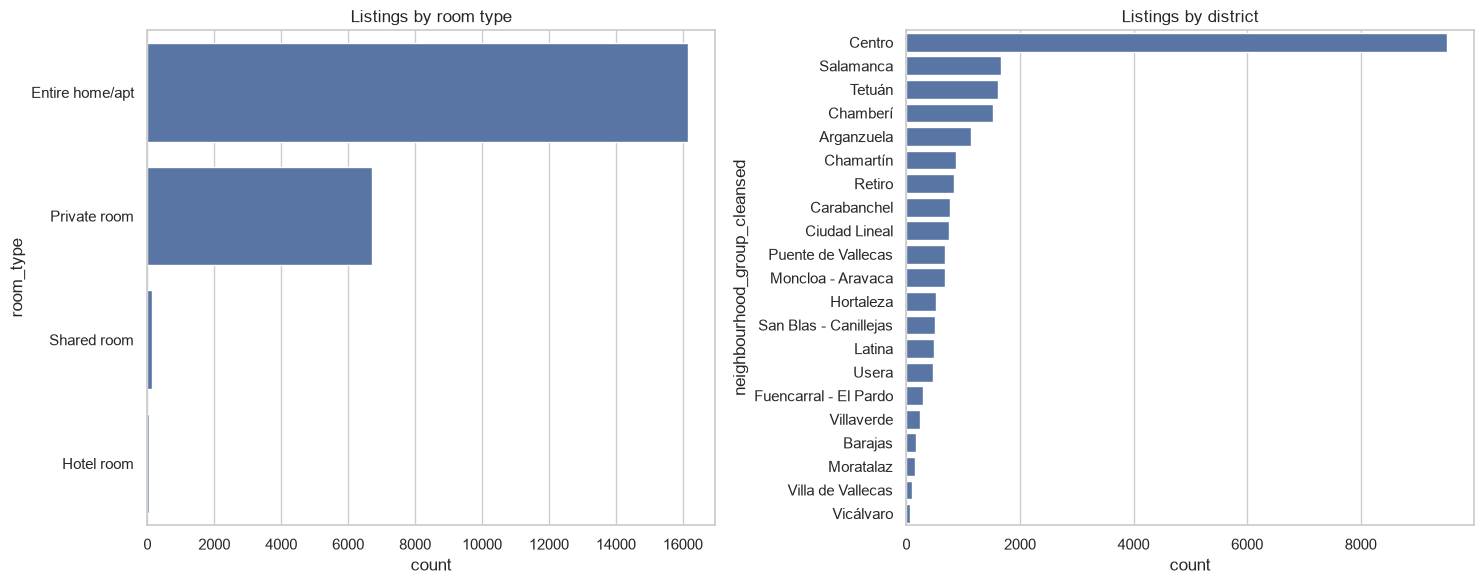

room_type
Entire home/apt    0.700
Private room       0.292
Shared room        0.007
Hotel room         0.002
Name: proportion, dtype: float64

Share of listings in Centro: 41.3%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.countplot(y=df["room_type"], order=df["room_type"].value_counts().index, ax=axes[0])
axes[0].set_title("Listings by room type")

sns.countplot(y=df["neighbourhood_group_cleansed"],
              order=df["neighbourhood_group_cleansed"].value_counts().index, ax=axes[1])
axes[1].set_title("Listings by district")

plt.tight_layout()
plt.show()

print(df["room_type"].value_counts(normalize=True).round(3))
print(f"\nShare of listings in Centro: {(df['neighbourhood_group_cleansed'] == 'Centro').mean():.1%}")

In [16]:
pt_counts = df["property_type"].value_counts()
print(pt_counts.head(10))
print(f"\nTop 10 property types cover {pt_counts.head(10).sum() / len(df):.1%} of listings")
print(f"Property types with fewer than 30 listings: {(pt_counts < 30).sum()} "
      f"({pt_counts[pt_counts < 30].sum()} listings)")

print(f"\nroom_type = 'Hotel room': {(df['room_type'] == 'Hotel room').sum()}")
print(f"property_type = 'Room in hotel': {(df['property_type'] == 'Room in hotel').sum()}")
print(df.loc[df["property_type"] == "Room in hotel", "room_type"].value_counts())

property_type
Entire rental unit             14554
Private room in rental unit     4523
Room in hotel                    584
Private room in home             574
Entire condo                     440
Entire loft                      383
Private room in hostel           305
Entire serviced apartment        288
Entire home                      280
Private room in condo            239
Name: count, dtype: int64

Top 10 property types cover 96.1% of listings
Property types with fewer than 30 listings: 42 (377 listings)

room_type = 'Hotel room': 39
property_type = 'Room in hotel': 584
room_type
Private room       582
Entire home/apt      1
Hotel room           1
Name: count, dtype: int64


In [17]:
rare_types = pt_counts[pt_counts < 30].index
is_rare = df["property_type"].isin(rare_types)

(df[is_rare]
 .groupby("property_type")
 .agg(n_listings=("id", "size"),
      n_with_price=("price", "count"),
      median_price=("price", "median"),
      room_type=("room_type", lambda s: s.mode()[0]))
 .sort_values("n_listings", ascending=False))

,n_listings,n_with_price,median_price,room_type
property_type,,,,
Room in hostel,29,20,154.000,Hotel room
Shared room in hotel,27,26,41.000,Shared room
Private room in serviced apartment,25,20,162.250,Private room
Private room in chalet,25,16,88.000,Private room
Shared room in hostel,25,19,34.000,Shared room
Private room in guest suite,23,10,50.785,Private room
Entire guest suite,21,19,156.350,Entire home/apt
Shared room in rental unit,21,17,36.110,Shared room
Private room in townhouse,19,17,66.830,Private room


In [18]:
df["property_type_grouped"] = df["property_type"].where(~is_rare, "Other (" + df["room_type"] + ")")

print(f"Categories: {df['property_type'].nunique()} -> {df['property_type_grouped'].nunique()}")
df.loc[is_rare, "property_type_grouped"].value_counts()

Categories: 60 -> 22


property_type_grouped
Other (Private room)       132
Other (Entire home/apt)    129
Other (Shared room)         84
Other (Hotel room)          32
Name: count, dtype: int64

In [19]:
nb_counts = df["neighbourhood_cleansed"].value_counts()
dist_counts = df["neighbourhood_group_cleansed"].value_counts()

print(f"Neighbourhoods: {len(nb_counts)} | with fewer than 30 listings: {(nb_counts < 30).sum()} "
      f"({nb_counts[nb_counts < 30].sum()} listings) | smallest: {nb_counts.min()}")
print(f"Districts:      {len(dist_counts)} | with fewer than 30 listings: {(dist_counts < 30).sum()} "
      f"| smallest: {dist_counts.min()} ({dist_counts.idxmin()})")

nb_counts.tail(10)

Neighbourhoods: 128 | with fewer than 30 listings: 27 (394 listings) | smallest: 1
Districts:      21 | with fewer than 30 listings: 0 | smallest: 62 (Vicálvaro)


neighbourhood_cleansed
Santa Eugenia     10
Palomas            9
El Goloso          7
Cuatro Vientos     6
Valdemarín         6
Pavones            6
Horcajo            4
Fuentelareina      4
El Pardo           2
Atalaya            1
Name: count, dtype: int64

### Findings and decisions on categorical features

- **No missing values** in the main categorical features.
- **`room_type`:** 70% of listings are entire homes and 29% private rooms; shared rooms (0.7%) and hotel rooms (0.2%) are marginal. The variable is kept as it is (4 categories).
- **`room_type` and `property_type` are inconsistent for hotels:** 582 of the 584 listings with `property_type = "Room in hotel"` are labelled as `"Private room"`, while most of the 39 `"Hotel room"` listings are actually hostel rooms. **Conclusion:** `room_type` cannot be used to identify hotels; `property_type` is more reliable for that purpose.
- **`property_type` has 60 categories, 42 of them with fewer than 30 listings** (377 listings, 1.6%). Some have 0–2 listings with price, so their price information is not reliable and a model would overfit them. The inspection shows that every rare category is a variant of one of the four room types (e.g. "Entire villa", "Private room in chalet"). **Action:** rare categories are grouped by their room type ("Other (Entire home/apt)", "Other (Private room)", etc.) into a new column `property_type_grouped` (60 → 22 categories). Grouping all of them into a single "Other" was rejected because it would mix entire villas with shared beds. The original column is kept.
- **Location:** the market is highly concentrated, with 41.3% of listings in the Centro district. `neighbourhood_cleansed` has 128 neighbourhoods, 27 of them with fewer than 30 listings (some with only 1–2), whereas the 21 districts (`neighbourhood_group_cleansed`) all have at least 62 listings. **Decision:** the model will use the **district** together with latitude and longitude, instead of the neighbourhood.

## 4. Low prices and length of stay

In [20]:
low = df[df["price"] < 26.5]
print(f"{len(low)} listings below 26.5 €/night (lower 1.5·IQR fence on the log scale)")
low["room_type"].value_counts()

324 listings below 26.5 €/night (lower 1.5·IQR fence on the log scale)


room_type
Private room       224
Shared room         67
Entire home/apt     33
Name: count, dtype: int64

In [21]:
df["quote_nights"] = (df["price_quote_checkout_date"] - df["price_quote_checkin_date"]).dt.days

cheap_entire = low[low["room_type"] == "Entire home/apt"].index
print(df.loc[cheap_entire, "quote_nights"].describe())

df.loc[cheap_entire, ["price", "price_quote_total_price", "quote_nights",
                      "minimum_nights", "availability_365", "host_id"]].sort_values("price").head(10)

count     33.000000
mean      98.181818
std       31.864414
min       30.000000
25%       90.000000
50%       90.000000
75%      120.000000
max      180.000000
Name: quote_nights, dtype: float64


,price,price_quote_total_price,quote_nights,minimum_nights,availability_365,host_id
7179,12.04,2167.86,180.0,NaN,0,4190343
15820,12.37,1113.04,90.0,90.0,1,490812264
3180,12.86,1542.81,120.0,NaN,0,232520062
3181,12.86,1542.67,120.0,NaN,0,232520062
9340,12.86,1542.67,120.0,NaN,0,232520062
9342,12.87,1544.98,120.0,NaN,0,232520062
5198,12.94,1553.09,120.0,NaN,0,232520062
3182,12.94,1552.80,120.0,NaN,0,232520062
10136,12.94,1553.08,120.0,NaN,0,232520062
7124,12.96,1555.13,120.0,NaN,0,232520062


In [22]:
print(df.groupby(df["quote_nights"] >= 30)["price"].agg(["count", "median"]))
print(f"\nListings with missing minimum_nights: {df['minimum_nights'].isna().sum()}")

              count   median
quote_nights                
False         16081  161.000
True           2666   93.225

Listings with missing minimum_nights: 1729


In [23]:
df["long_stay"] = (df["minimum_nights"] >= 30) | (df["quote_nights"] >= 30)

print(f"Listings with long stay (min. nights or price quote >= 30 nights): {df['long_stay'].mean():.1%}")
print(df.groupby("long_stay")["price"].agg(["count", "median"]))
df.shape

Listings with long stay (min. nights or price quote >= 30 nights): 15.7%
           count  median
long_stay               
False      15994  160.76
True        2753   95.22


(23071, 81)

### Findings and decisions on low prices

- **Low prices are not errors.** 324 listings are below the lower fence (26.5 €/night): 291 are private or shared rooms, for which low prices are plausible. The 33 entire homes all have **price quotes of 30 to 180 nights** (median 90).
- **How `price` is built:** Inside Airbnb obtains each price from a booking quote for specific dates (`price_quote_checkin_date` / `price_quote_checkout_date`), and `price` is the total quote divided by the number of nights. For example, a flat with a 120-night quote of 1,543 € has a "nightly" price of 12.86 €. For mid-term rentals, `price` is therefore a monthly rent expressed per night, not a tourist nightly price.
- **Consequence:** the nightly price strongly depends on the length of stay. Listings quoted for 30+ nights have a median price of 93 € vs 161 € for shorter quotes.
- **Action 1 – keep low prices:** they are real prices of a different market segment.
- **Action 2 – correct `long_stay`:** `minimum_nights` is missing for 1,729 listings, so the previous definition missed many mid-term rentals. `long_stay` is redefined as *minimum nights ≥ 30 **or** price quote ≥ 30 nights* (13.7% → 15.7% of listings). The new column `quote_nights` is also kept as a potential feature.
- **Recommendation for modelling:** since tourist stays and mid-term rentals are different markets, it should be evaluated in the modelling stage whether to train the model only on short stays or to keep both segments using `long_stay`.

## Summary and next steps

**Actions performed in this notebook** (input: 23,109 listings × 78 columns)

| Issue | Evidence | Action |
|---|---|---|
| Price strongly right-skewed (skewness 31.5) | Log transformation gives skewness 0.2 | Model `log(price)` |
| 38 extreme prices (> 2,921 €/night) | Placeholder prices: no reviews, available all year, mostly two hosts | **Removed** |
| Moderate price outliers (26.5–810 €) | Cheap rooms and mid-term rentals | Kept |
| 225 rooms with building-level size data | Hotel/hostel rooms with 18–50 bedrooms | `bedrooms`, `beds`, `bathrooms` set to `NaN` |
| Large entire homes above the 99th percentile | Consistent data (e.g. 8 bedrooms for 16 guests) | Kept (capping rejected) |
| `maximum_nights` | 67% default values | Kept, not recommended as a feature |
| 42 rare property types | Variants of the 4 room types, few listings | Grouped into `property_type_grouped` (60 → 22) |
| 128 neighbourhoods, some with 1–2 listings | 21 districts with ≥ 62 listings | Use district + latitude/longitude |
| Price depends on length of stay | 30+ night quotes: median 93 € vs 161 € | New `quote_nights`; `long_stay` refined (15.7%) |

**Output:** 23,071 listings × 81 columns, saved to `data/processed/listings_02.parquet`.

**Pending for the next stages**
- Listings without price (~19%) are kept here; their treatment is decided in notebook 01.
- Missing values in `bedrooms`, `beds` and `bathrooms` must be imputed in the modelling stage.
- Decide whether to model tourist stays and mid-term rentals together (using `long_stay`) or separately.

In [24]:
df.to_parquet("../data/processed/listings_02.parquet", index=False)
print(f"Saved: {df.shape[0]} listings × {df.shape[1]} columns")

Saved: 23071 listings × 81 columns
